In [3]:
import numpy as np
from USV_Model import USV_Model
from IPython.display import Image
from scipy.integrate import odeint

In [4]:
model = USV_Model()
dynamics = model.get_dynamics()

### How to use model

In [4]:
def odefun(q, time, thrust, angle):
    qdot = np.zeros_like(q)
    qdot[:3] = q[3:]
    qdot[3:] = dynamics(q, thrust, angle)
    return qdot

In [5]:
dt = 1/100
time = np.arange(0, 10, dt)
q0 = np.array([0, 0, 0, 0, 0, 0])

q_list = odeint(odefun, q0, time, args=(36, np.deg2rad(0)))

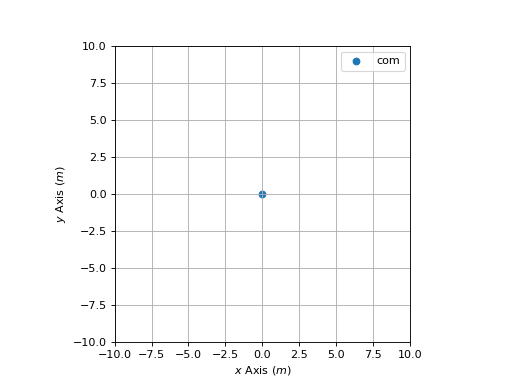

In [5]:
model.animate(q_list, dt)
gif_display = Image(filename='anim.gif')
display(gif_display)

### How to control with PD 

In [29]:
def PIDfun(q, t, q_ref, Kp=2, Kd=2, Kp_theta=20, Kd_theta=5):
    qdot = np.zeros_like(q)
    qdot[:3] = q[3:]

    Fx = Kp*(q_ref[0] - q[0]) + Kd*(q_ref[3] - q[3])
    Fy = Kp*(q_ref[1] - q[1]) + Kd*(q_ref[4] - q[4])

    #Outer Loop
    thrust_des = np.sqrt(Fx**2 + Fy**2)
    theta_des = np.arctan2(Fy, Fx) - np.pi/2

    #Inner Loop
    torque_des = Kp_theta*(theta_des - q[2]) + Kd_theta*(q_ref[5] - q[5])
    
    l = 1 #Boat lenght

    u_2 =  np.arcsin(-2*np.clip(torque_des, a_min=-thrust_des*(l/2), a_max=thrust_des*(l/2))/(l*thrust_des))

    u_1 = thrust_des

    qdot[3:] = dynamics(q, u_1, u_2)
    return qdot

In [37]:
dt = 1/100
time = np.arange(0, 10, dt)
q0 = np.array([-5, -5, 0, 0, 0, 0])
qref = np.array([5,5,0, 0,0,0])
q_list = odeint(PIDfun, q0, time, args=(qref,))

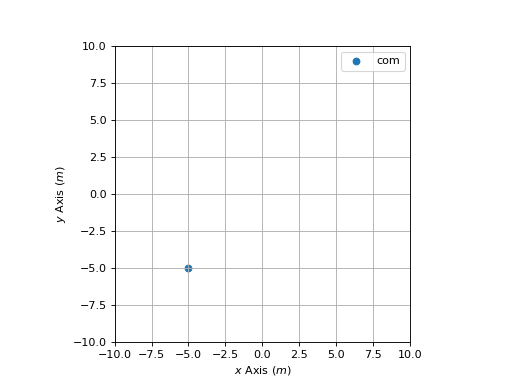

In [38]:
model.animate(q_list, dt)
gif_display = Image(filename='anim.gif')
display(gif_display)

### Linearize around setpoint

In [ ]:
#x_1, x_2, theta, dx_1, dx_2, dtheta
q = np.array([0,0,0, 0,0,0]) 

#Thrust force, angle (rad)
#u_1, u_2
u = np.array([0,0])

A, B = model.linearize_dynamic_model(q, u)
display(A)
display(B)

array([[ 0. ,  0. ,  0. ,  1. ,  0. ,  0. ],
       [ 0. ,  0. ,  0. ,  0. ,  1. ,  0. ],
       [ 0. ,  0. ,  0. ,  0. ,  0. ,  1. ],
       [ 0. ,  0. ,  0. , -0.2,  0. ,  0. ],
       [ 0. ,  0. ,  0. ,  0. , -0.2,  0. ],
       [ 0. ,  0. ,  0. ,  0. ,  0. , -2.4]])

array([[0. , 0. ],
       [0. , 0. ],
       [0. , 0. ],
       [0. , 0. ],
       [0.2, 0. ],
       [0. , 0. ]])

## Non-linear Inversion controller

Para más info check: https://www.aerostudents.com/courses/advanced-flight-control/nonlinearDynamicInversion.pdf

In [7]:
def NDI_controller(q, t, q_ref, m, c, l,
                   Kp=4.0, Kv=4.0,
                   Kp_theta=25.0, Kv_theta=8.0):
    """
    Nonlinear Dynamic Inversion controller for speedboat.
    Prioritizes position tracking; heading tracks with resulting torque.
    """
    I = m * l**2 / 12
    x, y, th, xd, yd, thd = q
    x_r, y_r, th_r, xd_r, yd_r, thd_r, xdd_r, ydd_r, thdd_r = q_ref
    
    if t > 5: 
        x_r, y_r = -5,-8 


    # --- Desired accelerations (PD + feedforward) ---
    ax_des = xdd_r + Kv*(xd_r - xd) + Kp*(x_r - x)
    ay_des = ydd_r + Kv*(yd_r - yd) + Kp*(y_r - y)
    
    # --- Invert drag to get required world-frame forces ---
    Fx_des = m*ax_des + c*xd
    Fy_des = m*ay_des + c*yd
    
    # --- Invert actuation model ---
    # From dynamics: Fx = -u1*sin(u2 + th), Fy = u1*cos(u2 + th)
    # So: atan2(-Fx, Fy) = u2 + th
    alpha = np.arctan2(-Fx_des, Fy_des)
    u2 = alpha - th
    u1 = np.hypot(Fx_des, Fy_des)
    
    # Handle near-zero thrust
    if u1 < 1e-6:
        u1 = 0.0
        u2 = 0.0
    
    # Normalize u2 to [-pi, pi]
    u2 = np.arctan2(np.sin(u2), np.cos(u2))
    
    # --- State derivatives ---
    qdot = np.zeros(6)
    qdot[:3] = q[3:]  # velocities
    qdot[3:] = dynamics(q, u1, u2)  # accelerations from plant
    
    return qdot


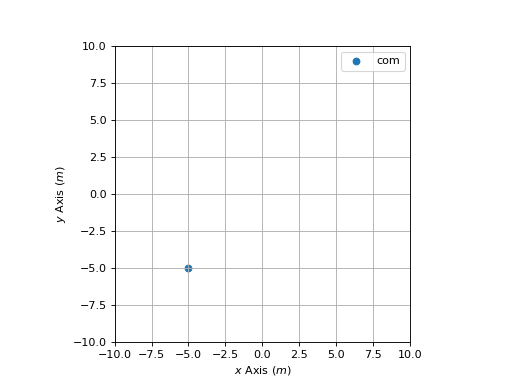

In [8]:
dt = 1/100
time = np.arange(0, 10, dt)
q0 = np.array([-5, -5, 0, 0, 0, 0])
qref = np.array([5,5,0, 0,0,0,0,0,0])
q_list = odeint(NDI_controller, q0, time, args=(qref,model.m,model.c,model.l,))

model.animate(q_list, dt)
gif_display = Image(filename='anim.gif')
display(gif_display)